# Data Quality and Landing Labels

## tl;dr
Validate launch keys and known outcomes, derive the binary target, and distinguish missing landing-pad information from missing labels.

## Context & Methods
IBM course project, reproduced from attributed historical snapshots. See `data/source_manifest.json` for URLs and hashes.

### Key Assumptions
Course success labels include controlled ocean landings; descriptive associations are not causal effects.

## Data
Run from a clean kernel. All ordinary analysis uses included source snapshots.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'falcon9').exists() else Path.cwd().parent
if not (ROOT / 'falcon9').exists():
    raise RuntimeError('Start Jupyter in the repository root or notebooks directory')
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from falcon9.analysis import load_data, group_summary
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
df = load_data()


### Validate row grain and source missingness

In [2]:
raw = pd.read_csv(ROOT / 'data/raw/dataset_part_1.csv')
display(raw.isna().sum().rename('missing_rows').to_frame())
assert df.FlightNumber.is_unique
assert len(df) == len(raw)
print('Unique launches:', len(df))

Unique launches: 90


,missing_rows
FlightNumber,0
Date,0
BoosterVersion,0
PayloadMass,0
Orbit,0
LaunchSite,0
Outcome,0
Flights,0
GridFins,0
Reused,0


## Results
### Audit label mapping

In [3]:
from falcon9.analysis import OUTCOMES
audit = df.groupby('Outcome').agg(launches=('Class','size'), Class=('Class','first'))
display(audit)
provided = pd.read_csv(ROOT / 'data/raw/dataset_part_2.csv')
joined = df[['FlightNumber','Class']].merge(provided[['FlightNumber','Class']], on='FlightNumber', validate='one_to_one', suffixes=('_derived','_course'))
assert len(joined) == len(df)
assert joined.Class_derived.equals(joined.Class_course)
print('Derived labels match the course snapshot for all launches.')

Derived labels match the course snapshot for all launches.


,launches,Class
Outcome,,
False ASDS,6,0
False Ocean,2,0
False RTLS,1,0
None ASDS,2,0
None None,19,0
True ASDS,41,1
True Ocean,5,1
True RTLS,14,1


### Class balance

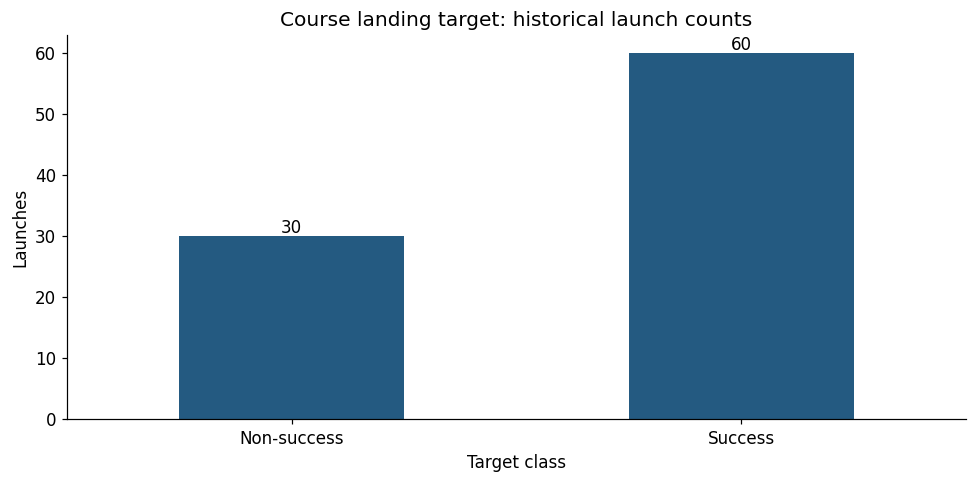

In [4]:
counts = df.Class.value_counts().reindex([0,1])
ax = counts.plot.bar(color='#245a81', rot=0)
ax.set_xticklabels(['Non-success','Success'])
ax.set(title='Course landing target: historical launch counts', xlabel='Target class', ylabel='Launches')
for i, value in enumerate(counts): ax.text(i, value+0.5, str(value), ha='center')
plt.tight_layout(); plt.show()

### Export the validated analytical table

In [5]:
target = ROOT / 'data/processed'
target.mkdir(exist_ok=True)
df.to_csv(target / 'launches.csv', index=False)
print('Saved data/processed/launches.csv')

Saved data/processed/launches.csv


## Takeaways
Class 0 includes unknown/no-attempt outcomes; Class 1 includes controlled ocean landings. PayloadMass is already imputed upstream, so it is retained for descriptive analysis but excluded from primary modeling. Cumulative ReusedCount, target-derived Outcome, and identifiers are also excluded from predictors.